In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar opções de exibição para mostrar todas as colunas
pd.set_option('display.max_columns', None)

# Definir o caminho do arquivo
file_path = '/content/olist dados para analise.xlsx'

# Carregar o arquivo Excel
xls = pd.ExcelFile(file_path)

# Ler as planilhas em DataFrames usando os nomes fornecidos pelo usuário
try:
    df_customer = pd.read_excel(xls, sheet_name='Customer')
    df_orders = pd.read_excel(xls, sheet_name='Orders')
    df_order_items = pd.read_excel(xls, sheet_name='Order Itens')
    df_sellers = pd.read_excel(xls, sheet_name='Sellers')
    df_review = pd.read_excel(xls, sheet_name='Reviews') # Carregar a nova planilha 'Reviews'
except Exception as e:
    print(f"Erro ao ler as planilhas. Por favor, verifique se os nomes das planilhas são exatamente 'Customer', 'Orders', 'Order Itens', 'Sellers' e 'Reviews'. Detalhes do erro: {e}")
    raise e

# Unificar 'customer' com 'order' utilizando a coluna 'customer_id'
merged_df = pd.merge(df_customer, df_orders, on='customer_id', how='inner')

# Unificar o resultado com 'order itens' utilizando a coluna 'order_id'
merged_df = pd.merge(merged_df, df_order_items, on='order_id', how='inner')

# Unificar o resultado com 'sellers' utilizando a coluna 'seller_id'
merged_df = pd.merge(merged_df, df_sellers, on='seller_id', how='inner')

# Unificar o resultado com 'Review' utilizando a coluna 'order_id'
merged_df = pd.merge(merged_df, df_review, on='order_id', how='inner')

# Exibir as primeiras linhas do DataFrame unificado
print("Cabeçalho do DataFrame unificado:")
print(merged_df.head())

# Exibir o formato (número de linhas e colunas) do DataFrame unificado
print("\nFormato do DataFrame unificado:", merged_df.shape)

Cabeçalho do DataFrame unificado:
                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   
3  b2b6027bc5c5109e529d4dc6358b12c3  259dac757896d24d7702b9acbbff3f3c   
4  4f2d8ab171c80ec8364f7c12e35b23ad  345ecd01c38d18a9036ed96c73b8d066   

   customer_zip_code_prefix          customer_city customer_state  \
0                     14409                 franca             SP   
1                      9790  sao bernardo do campo             SP   
2                      1151              sao paulo             SP   
3                      8775        mogi das cruzes             SP   
4                     13056               campinas             SP   

                           order_id order_status  order_purchase_timestamp  \
0  00e7ee1b050b8499577073aeb2a297a

In [14]:
# === CONFIGURAÇÃO VISUAL PROFISSIONAL ===
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 120,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
})

# Paleta de cores padrão do projeto
COR_PRINCIPAL = '#2E86AB'    # Azul profissional
COR_ALERTA    = '#E74C3C'    # Vermelho para problemas
COR_SUCESSO   = '#27AE60'    # Verde para positivo
COR_NEUTRO    = '#95A5A6'    # Cinza neutro
COR_DESTAQUE  = '#F39C12'    # Laranja destaque
COR_LINHA     = '#E74C3C'    # Vermelho para linhas de tendência

print("✅ Tema profissional carregado com sucesso!")


✅ Tema profissional carregado com sucesso!


In [15]:
merged_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,seller_zip_code_prefix,seller_city,seller_state,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,42871.628877,42871.640417,42878.449965,42880.441377,42891,1,a9516a079e37a9c9c36b9b78b10169e8,7c67e1448b00f6e969d365cea6b010ab,42877.640417,124.99,21.88,8577,itaquaquecetuba,SP,88b8b52d46df026a9d1ad2136a59b30b,4,NaN,NaN,42881.0,42885.940741
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,43112.866944,43112.873981,43115.718738,43129.528692,43137,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,43118.873981,289.00,46.48,88303,itajai,SC,02fc48a9efa3e3d0f1a8ea26507eeec3,5,NaN,NaN,43130.0,43141.946863
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,43239.672049,43240.679977,43262.604861,43265.749201,43264,1,bd07b66896d6f1494f5b86251848ced7,7c67e1448b00f6e969d365cea6b010ab,43256.679977,139.94,17.79,8577,itaquaquecetuba,SP,5ad6695d76ee186dc473c42706984d87,5,NaN,NaN,43266.0,43266.507627
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,43172.671273,43172.728692,43186.974097,43187.669734,43200,1,a5647c44af977b148e0a3a4751a09e2e,7c67e1448b00f6e969d365cea6b010ab,43186.688380,149.94,23.36,8577,itaquaquecetuba,SP,059a801bb31f6aab2266e672cab87bc5,5,NaN,NaN,43188.0,43192.775544
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,43310.410764,43310.423715,43311.636111,43321.872083,43327,1,9391a573abe00141c56e38d84d7d5b3b,4a3ca9315b744ce9f8e9374361493884,43312.423715,230.00,22.25,14940,ibitinga,SP,8490879d58d6c5d7773f2739a03f089a,5,a melhor nota,O baratheon è esxelente Amo adoro o baratheon,43322.0,43329.083241


## Preparação de Dados: Conversão de Datas

As colunas de data no DataFrame estão atualmente no formato de número de série do Excel. Transformando em objetos datetime adequados para facilitar a análise e a plotagem.

In [16]:
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'shipping_limit_date'
]

for col in date_columns:
    # Converter datas seriais do Excel para objetos datetime
    merged_df[col] = pd.to_datetime(merged_df[col], unit='D', origin='1899-12-30')

# Exibir as informações para verificar os tipos de dados
print("Informações do merged_df após a conversão de datas:")
merged_df.info()

Informações do merged_df após a conversão de datas:
<class 'pandas.DataFrame'>
RangeIndex: 112372 entries, 0 to 112371
Data columns (total 27 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   customer_id                    112372 non-null  str           
 1   customer_unique_id             112372 non-null  str           
 2   customer_zip_code_prefix       112372 non-null  int64         
 3   customer_city                  112372 non-null  str           
 4   customer_state                 112372 non-null  str           
 5   order_id                       112372 non-null  str           
 6   order_status                   112372 non-null  str           
 7   order_purchase_timestamp       112372 non-null  datetime64[ns]
 8   order_approved_at              112357 non-null  datetime64[ns]
 9   order_delivered_carrier_date   111188 non-null  datetime64[ns]
 10  order_delivered_customer_da

## 1. Vendas ao longo do tempo | Pedidos e receita por mês


Este conjunto de gráficos de linha apresenta a evolução do número total de pedidos e da receita total ao longo do tempo, em uma base mensal. O primeiro gráfico, 'Total de Pedidos ao Longo do Tempo (Mensal)', mostra a contagem de pedidos únicos para cada mês. O segundo, 'Receita Total ao Longo do Tempo (Mensal)', ilustra a soma total das vendas geradas por mês. Ambos os gráficos permitem identificar tendências sazonais, picos de vendas ou períodos de declínio, fornecendo uma visão geral do desempenho comercial ao longo do tempo.

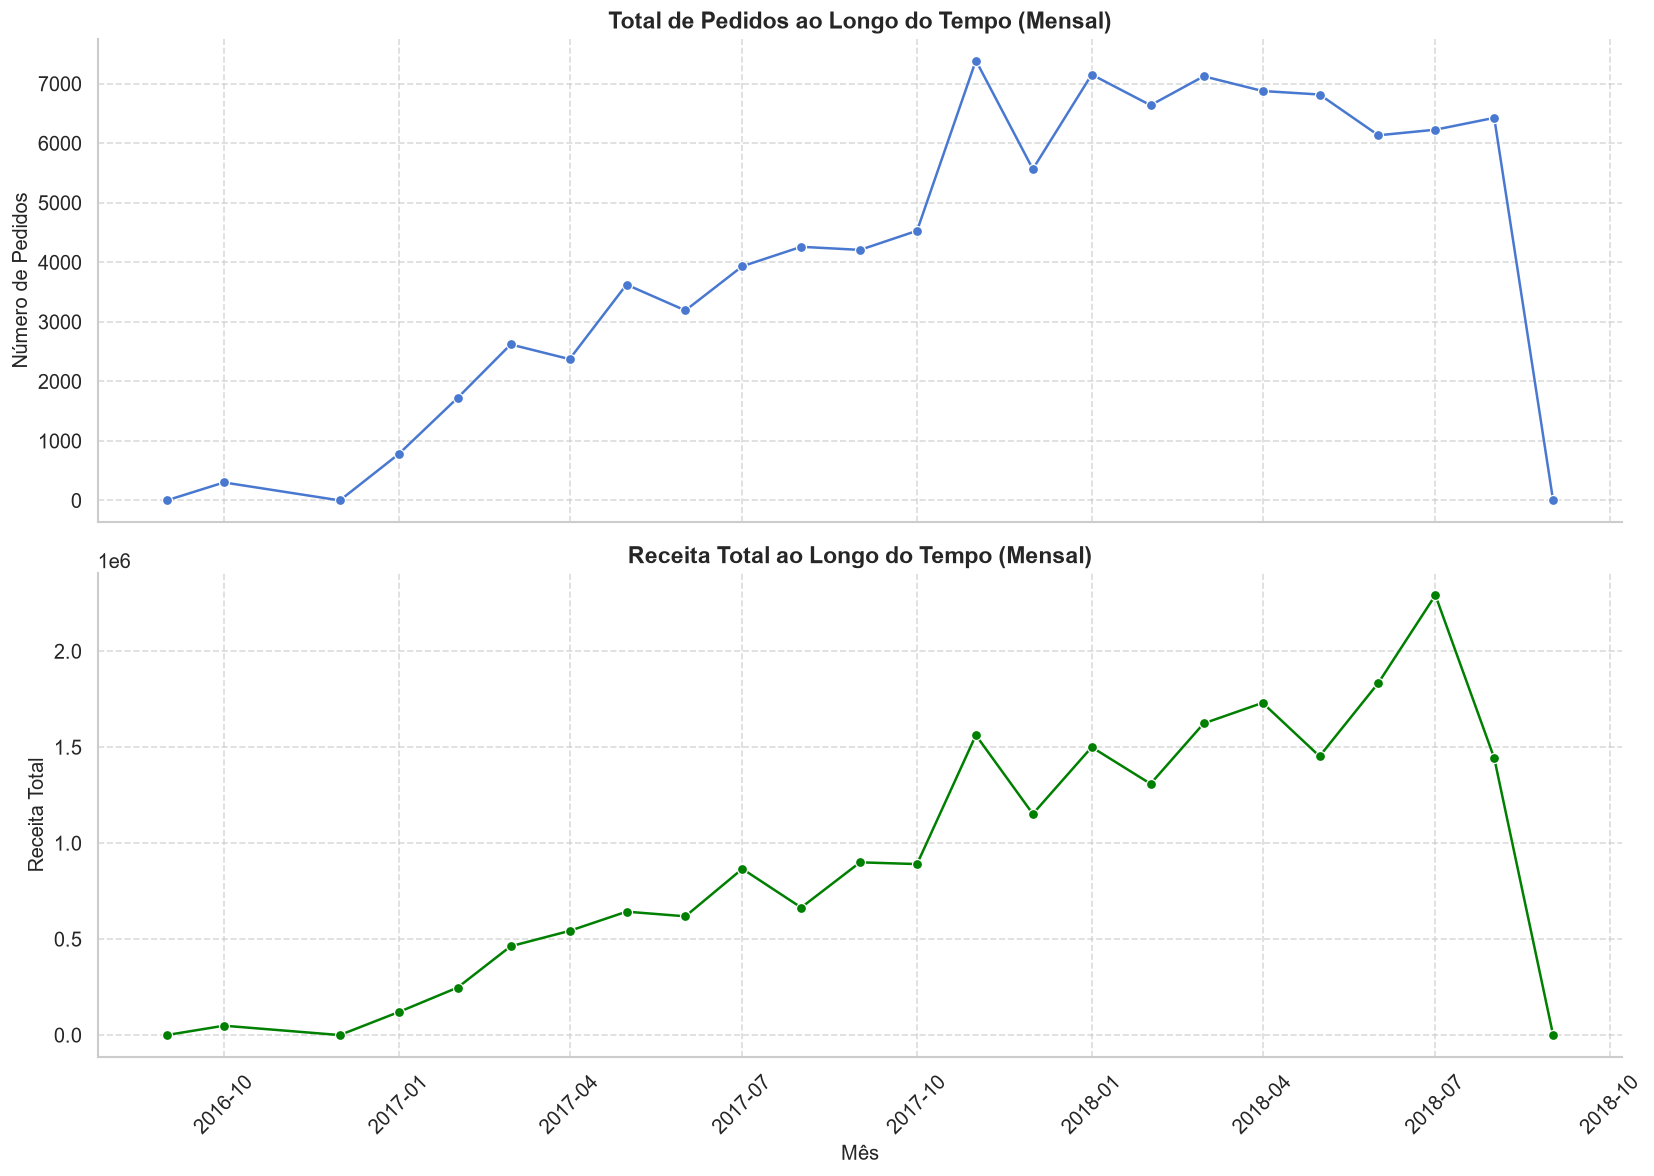

In [17]:
# Extrair mês e ano do timestamp de compra
merged_df['purchase_month_year'] = merged_df['order_purchase_timestamp'].dt.to_period('M')

# Agregar dados por mês
monthly_data = merged_df.groupby('purchase_month_year').agg(
    total_orders=('order_id', 'nunique'),
    total_revenue=('price', 'sum')
).reset_index()

# Converter 'purchase_month_year' de volta para datetime para plotagem
monthly_data['purchase_month_year'] = monthly_data['purchase_month_year'].dt.to_timestamp()

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Plotar Total de Pedidos por Mês
sns.lineplot(ax=axes[0], x='purchase_month_year', y='total_orders', data=monthly_data, marker='o')
axes[0].set_title('Total de Pedidos ao Longo do Tempo (Mensal)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Número de Pedidos')
axes[0].grid(True, linestyle='--', alpha=0.7)

# Plotar Receita Total por Mês
sns.lineplot(ax=axes[1], x='purchase_month_year', y='total_revenue', data=monthly_data, marker='o', color='green')
axes[1].set_title('Receita Total ao Longo do Tempo (Mensal)')
axes[1].set_xlabel('Mês')
axes[1].set_ylabel('Receita Total')
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2. Entregas no prazo × atrasadas | Percentual de pedidos entregues após a data estimada, por estado ou mês


Este conjunto de gráficos analisa o desempenho de entrega. O primeiro gráfico de barras, 'Percentual de Entregas Atrasadas por Estado do Cliente', exibe a proporção de entregas que ocorreram após a data estimada em cada estado do cliente. Ele ajuda a identificar quais estados apresentam maiores desafios em termos de pontualidade na entrega. O segundo gráfico de linha, 'Percentual de Entregas Atrasadas ao Longo do Tempo (Mensal)', mostra a variação do percentual de entregas atrasadas mês a mês, permitindo a visualização de tendências e a identificação de períodos com maior ou menor eficiência na entrega.

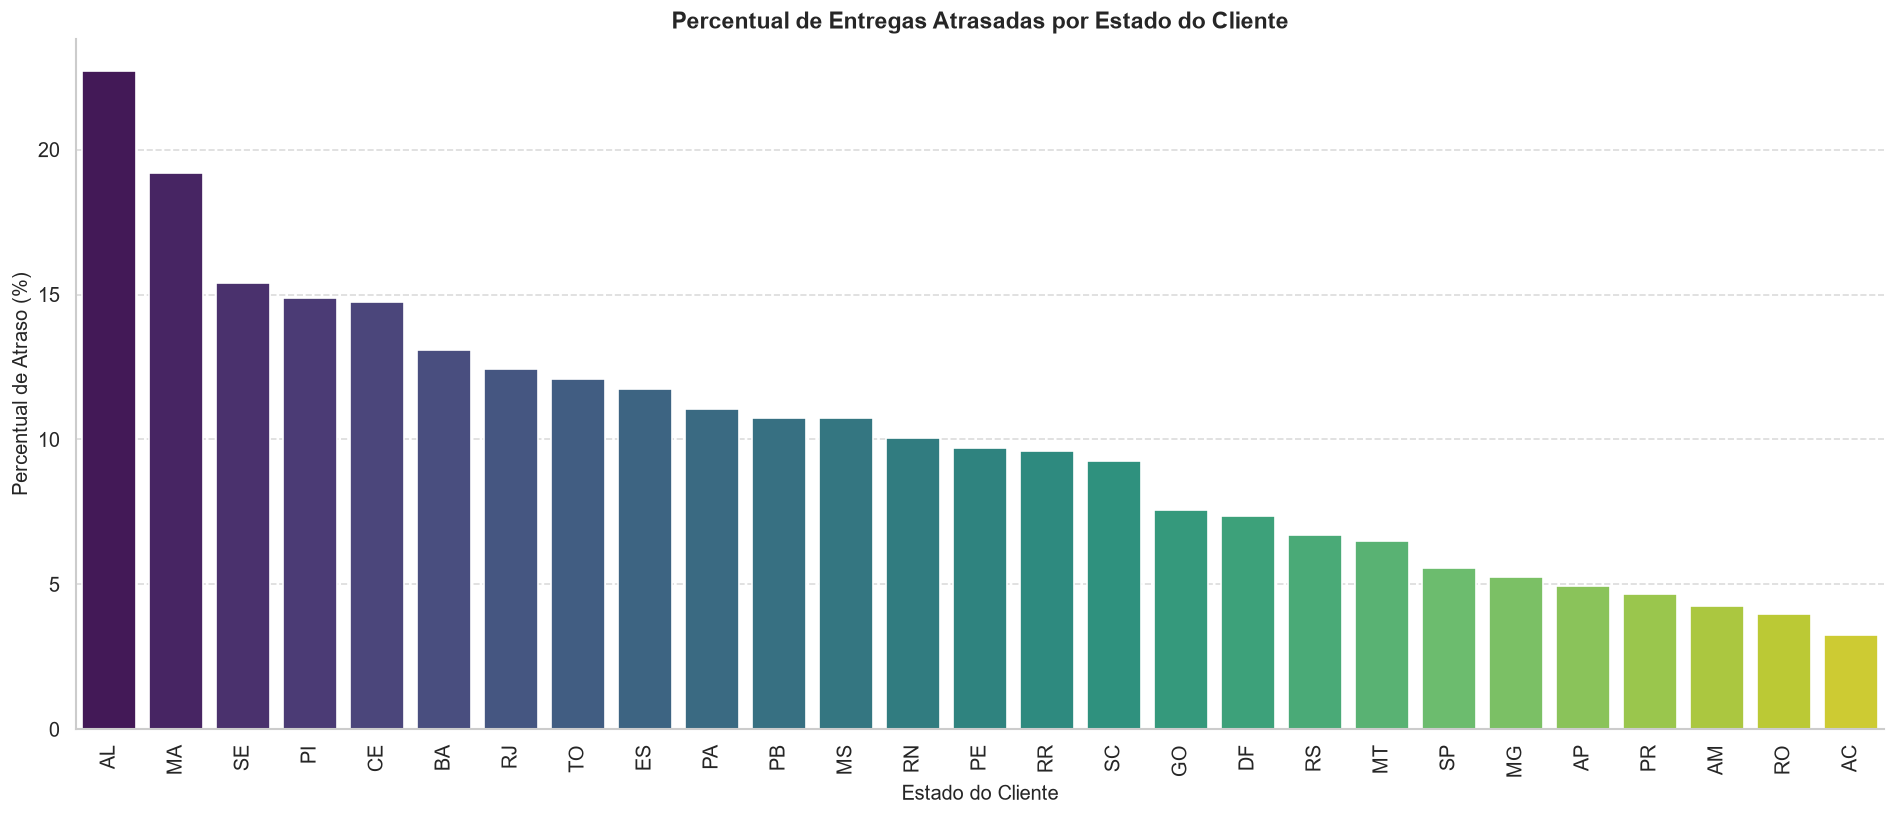

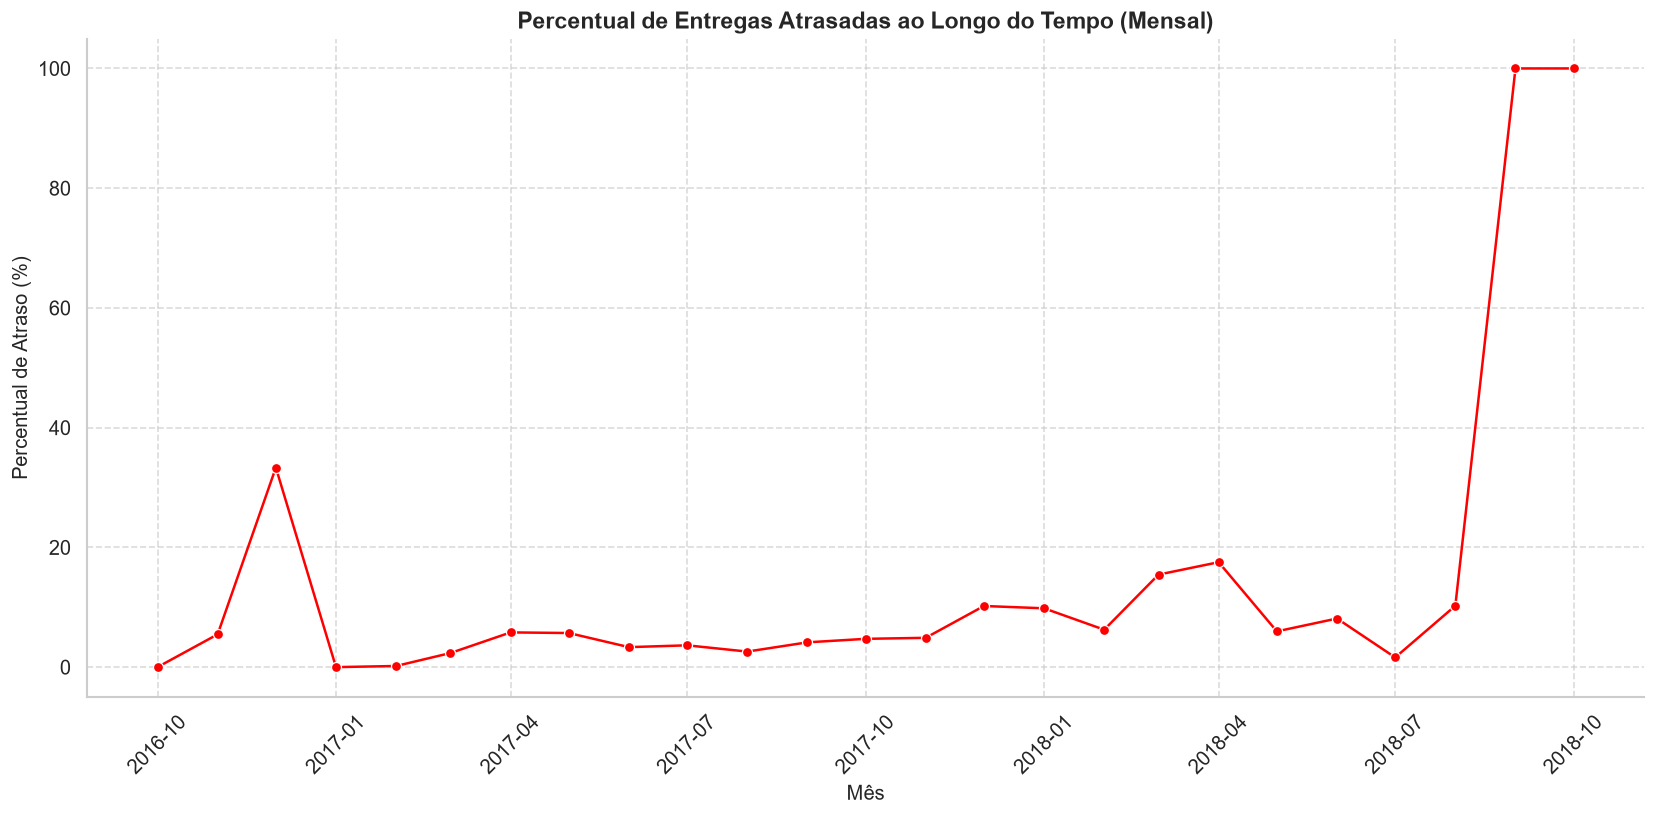

In [18]:
# Calcular status da entrega: True se atrasada, False se no prazo ou adiantada
merged_df['is_late_delivery'] = merged_df['order_delivered_customer_date'] > merged_df['order_estimated_delivery_date']

# --- Por Estado ---
late_delivery_by_state = merged_df.groupby('customer_state')['is_late_delivery'].value_counts(normalize=True).unstack(fill_value=0) * 100
late_delivery_by_state = late_delivery_by_state.rename(columns={False: 'On_Time_Percentage', True: 'Late_Percentage'})
late_delivery_by_state = late_delivery_by_state.sort_values(by='Late_Percentage', ascending=False).reset_index()

plt.figure(figsize=(16, 7))
sns.barplot(x='customer_state', y='Late_Percentage', data=late_delivery_by_state, palette='viridis')
plt.title('Percentual de Entregas Atrasadas por Estado do Cliente')
plt.xlabel('Estado do Cliente')
plt.ylabel('Percentual de Atraso (%)')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# --- Por Mês ---
# Extrair mês e ano da data de entrega
merged_df['delivery_month_year'] = merged_df['order_delivered_customer_date'].dt.to_period('M')

late_delivery_by_month = merged_df.groupby('delivery_month_year')['is_late_delivery'].value_counts(normalize=True).unstack(fill_value=0) * 100
late_delivery_by_month = late_delivery_by_month.rename(columns={False: 'On_Time_Percentage', True: 'Late_Percentage'})
late_delivery_by_month = late_delivery_by_month.reset_index()

# Converter 'delivery_month_year' de volta para datetime para plotagem
late_delivery_by_month['delivery_month_year'] = late_delivery_by_month['delivery_month_year'].dt.to_timestamp()

plt.figure(figsize=(14, 7))
sns.lineplot(x='delivery_month_year', y='Late_Percentage', data=late_delivery_by_month, marker='o', color='red')
plt.title('Percentual de Entregas Atrasadas ao Longo do Tempo (Mensal)')
plt.xlabel('Mês')
plt.ylabel('Percentual de Atraso (%)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Nota média e percentual de notas 1–2 para entregas no prazo e atrasadas

Este gráfico compara a nota média de avaliação e o percentual de avaliações baixas (1 ou 2 estrelas) para entregas realizadas no prazo e entregas atrasadas. Ele nos ajuda a entender o impacto da pontualidade da entrega na satisfação do cliente, medida pelas avaliações. Geralmente, espera-se que entregas atrasadas resultem em notas de avaliação mais baixas e um percentual maior de avaliações negativas, indicando a importância de um processo de entrega eficiente para a experiência do cliente.

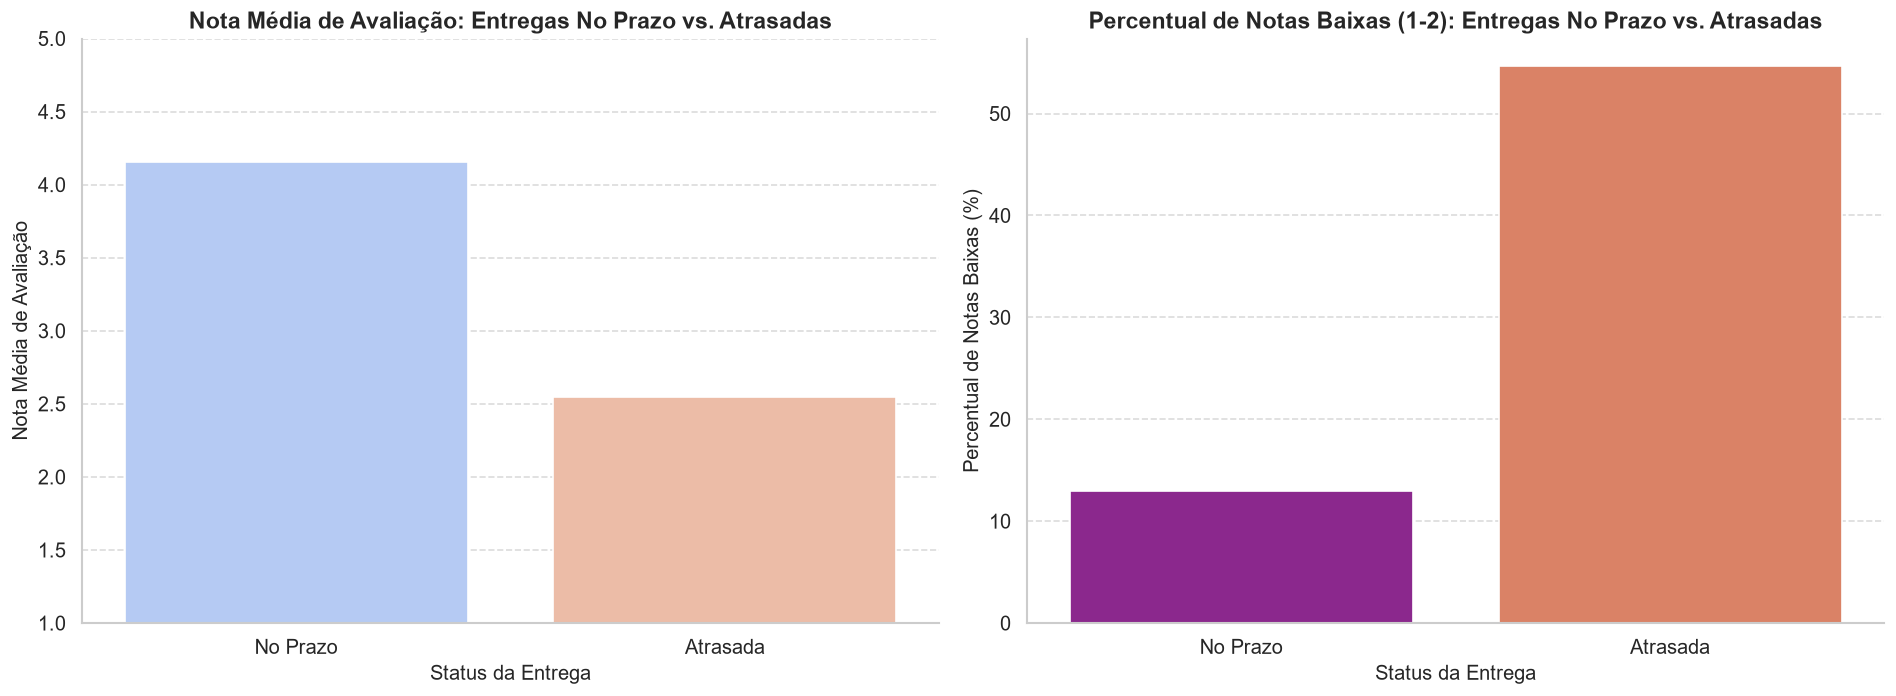

In [19]:
import numpy as np

# Calcular pontuação média de avaliação para entregas no prazo vs. atrasadas
review_scores_by_delivery = merged_df.groupby('is_late_delivery')['review_score'].mean().reset_index()
review_scores_by_delivery['is_late_delivery'] = review_scores_by_delivery['is_late_delivery'].map({True: 'Atrasada', False: 'No Prazo'})

# Calcular percentual de notas de avaliação baixas (1 ou 2) para entregas no prazo vs. atrasadas
merged_df['is_low_review_score'] = merged_df['review_score'].isin([1, 2])
low_review_percentage_by_delivery = merged_df.groupby('is_late_delivery')['is_low_review_score'].mean().reset_index()
low_review_percentage_by_delivery['is_low_review_score'] = low_review_percentage_by_delivery['is_low_review_score'] * 100 # Converter para percentual
low_review_percentage_by_delivery['is_late_delivery'] = low_review_percentage_by_delivery['is_late_delivery'].map({True: 'Atrasada', False: 'No Prazo'})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plotar Pontuação Média de Avaliação
sns.barplot(ax=axes[0], x='is_late_delivery', y='review_score', data=review_scores_by_delivery, palette='coolwarm')
axes[0].set_title('Nota Média de Avaliação: Entregas No Prazo vs. Atrasadas')
axes[0].set_xlabel('Status da Entrega')
axes[0].set_ylabel('Nota Média de Avaliação')
axes[0].set_ylim(1, 5) # As pontuações de avaliação são de 1 a 5
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Plotar Percentual de Notas Baixas (1 ou 2)
sns.barplot(ax=axes[1], x='is_late_delivery', y='is_low_review_score', data=low_review_percentage_by_delivery, palette='plasma')
axes[1].set_title('Percentual de Notas Baixas (1-2): Entregas No Prazo vs. Atrasadas')
axes[1].set_xlabel('Status da Entrega')
axes[1].set_ylabel('Percentual de Notas Baixas (%)')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## 4. Prioridades por região | Para cada estado: volume de pedidos e percentual de atraso


Este conjunto de gráficos de barras visa identificar as prioridades regionais com base no volume de pedidos e no percentual de atrasos na entrega. O primeiro gráfico, 'Top 15 Estados por Volume de Pedidos', mostra os estados com o maior número de pedidos, indicando as regiões de maior demanda. O segundo gráfico, 'Top 15 Estados por Percentual de Atraso na Entrega', destaca os estados com a maior proporção de entregas atrasadas. Juntos, esses gráficos ajudam a identificar as áreas onde a empresa tem um alto volume de negócios, mas também enfrenta desafios significativos na entrega, sugerindo onde os esforços de melhoria logística devem ser concentrados para maximizar a satisfação do cliente e a eficiência operacional.

Prioridades Regionais (ordenadas por uma pontuação combinada de volume de pedidos e percentual de atraso):


,customer_state,Total_Orders,Late_Percentage,Priority_Score
0,SP,41109,5.567628,228879.619823
1,RJ,12598,12.441250,156734.863146
2,MG,11466,5.270786,60434.828375
3,BA,3319,13.090813,43448.406798
4,RS,5412,6.719872,36367.948923
5,SC,3584,9.263715,33201.154957
6,ES,1998,11.756817,23490.120697
7,PR,4972,4.654812,23143.723849
8,CE,1317,14.741848,19415.013587
9,PE,1631,9.688196,15801.447661


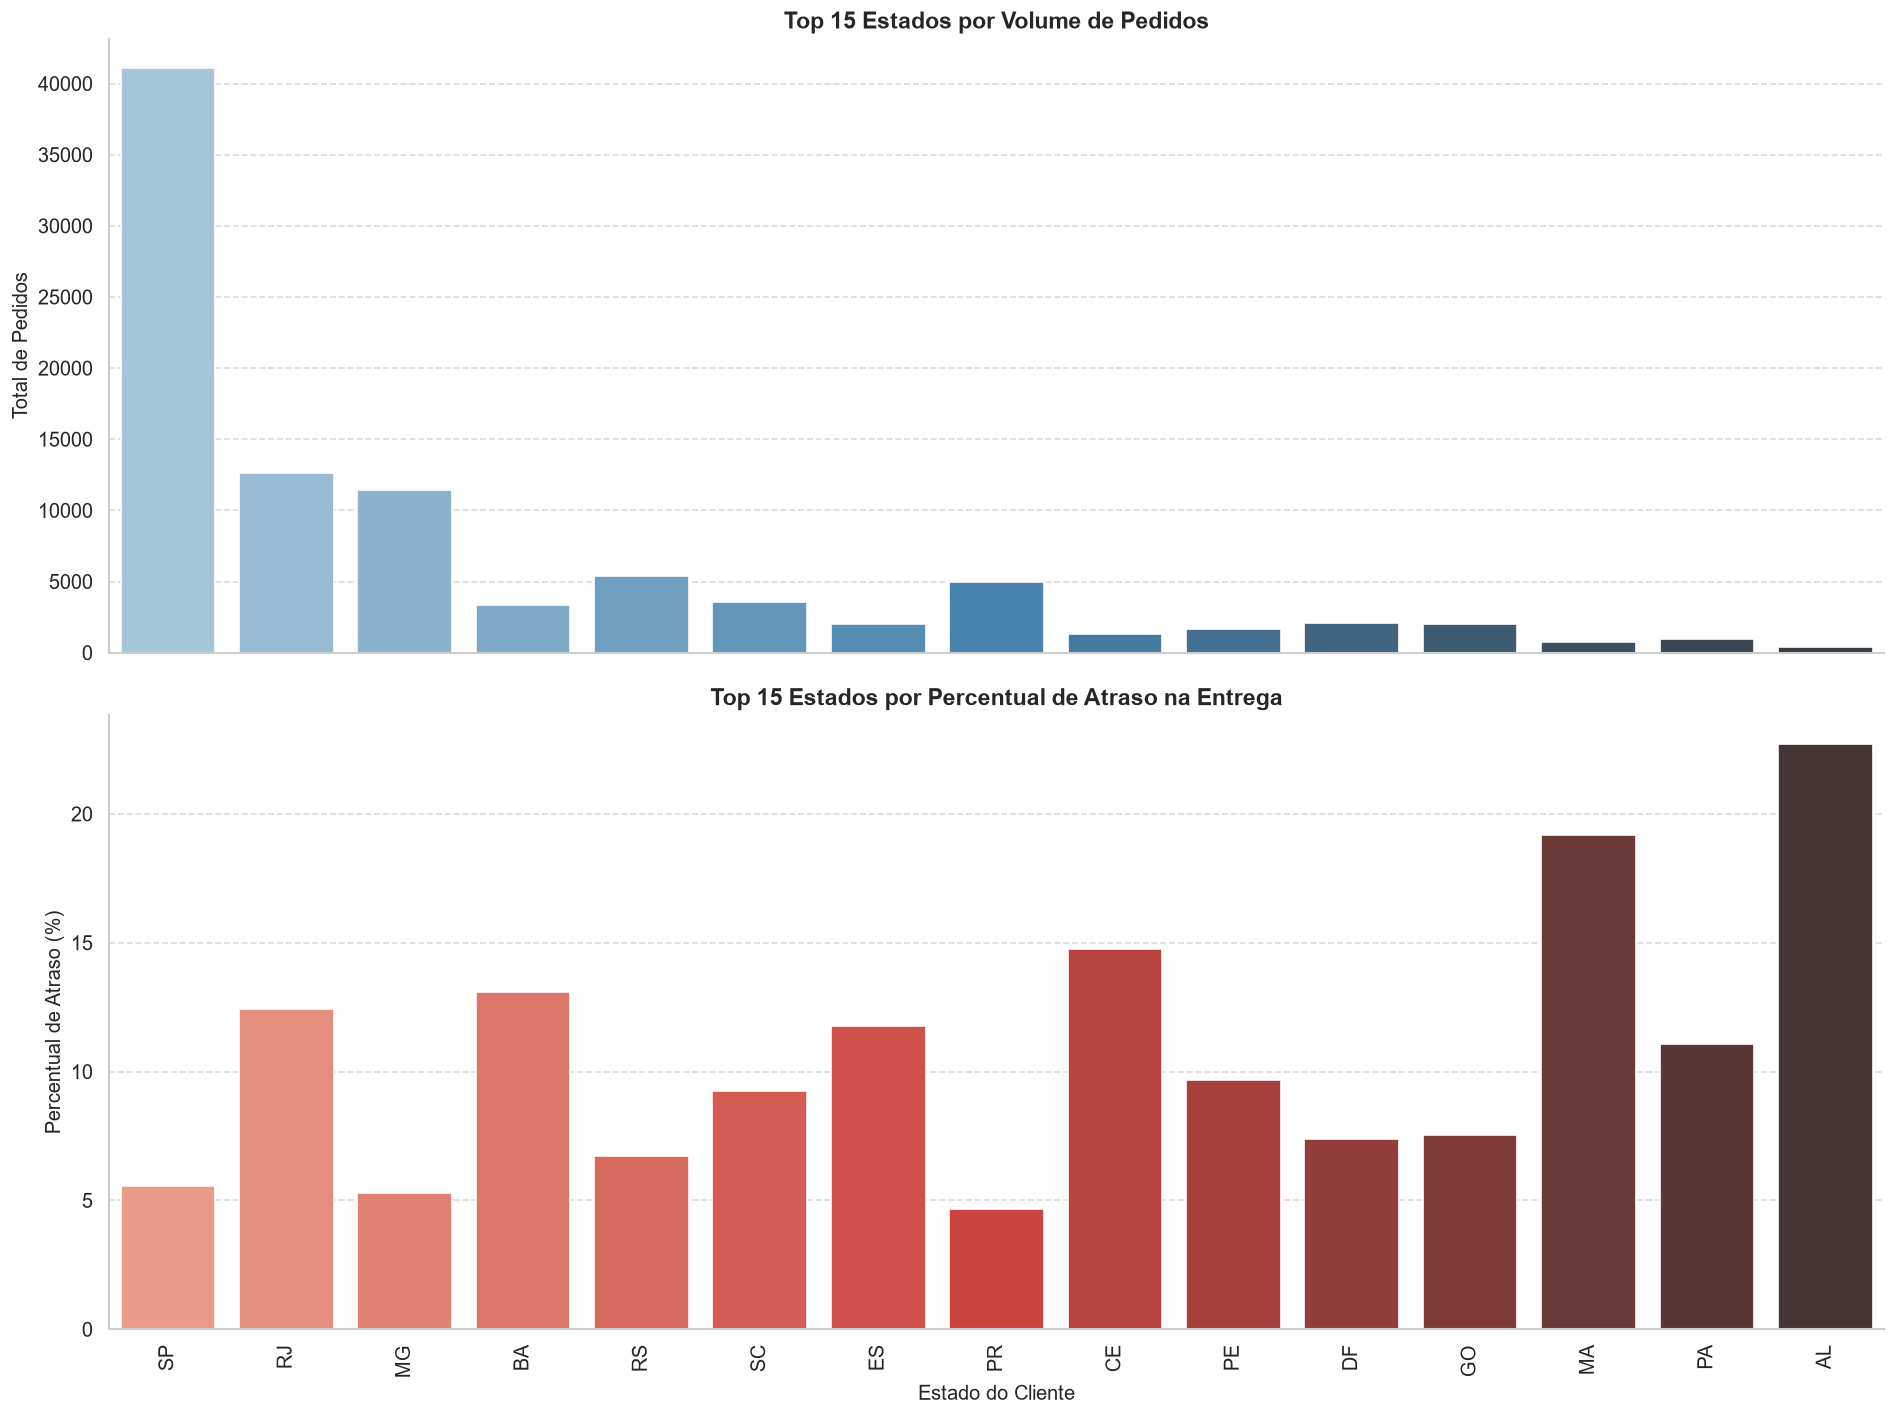

In [20]:
# Calcular total de pedidos por estado
order_volume_by_state = merged_df.groupby('customer_state')['order_id'].nunique().reset_index()
order_volume_by_state = order_volume_by_state.rename(columns={'order_id': 'Total_Orders'})

# Mesclar com o percentual de entregas atrasadas calculado anteriormente
regional_priorities = pd.merge(order_volume_by_state, late_delivery_by_state[['customer_state', 'Late_Percentage']], on='customer_state')

# Ordenar por total de pedidos e percentual de atraso para destacar prioridades
regional_priorities['Priority_Score'] = regional_priorities['Total_Orders'] * regional_priorities['Late_Percentage']
regional_priorities = regional_priorities.sort_values(by='Priority_Score', ascending=False).reset_index(drop=True)

print("Prioridades Regionais (ordenadas por uma pontuação combinada de volume de pedidos e percentual de atraso):")
display(regional_priorities.head(10))

# Visualizar os principais estados por volume de pedidos e percentual de atraso
fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=True)

sns.barplot(ax=axes[0], x='customer_state', y='Total_Orders', data=regional_priorities.head(15), palette='Blues_d')
axes[0].set_title('Top 15 Estados por Volume de Pedidos')
axes[0].set_ylabel('Total de Pedidos')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

sns.barplot(ax=axes[1], x='customer_state', y='Late_Percentage', data=regional_priorities.head(15), palette='Reds_d')
axes[1].set_title('Top 15 Estados por Percentual de Atraso na Entrega')
axes[1].set_xlabel('Estado do Cliente')
axes[1].set_ylabel('Percentual de Atraso (%)')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 📊 Análise Operacional e Estratégica
Gráficos analíticos com foco em **insights acionáveis** para a operação Olist.


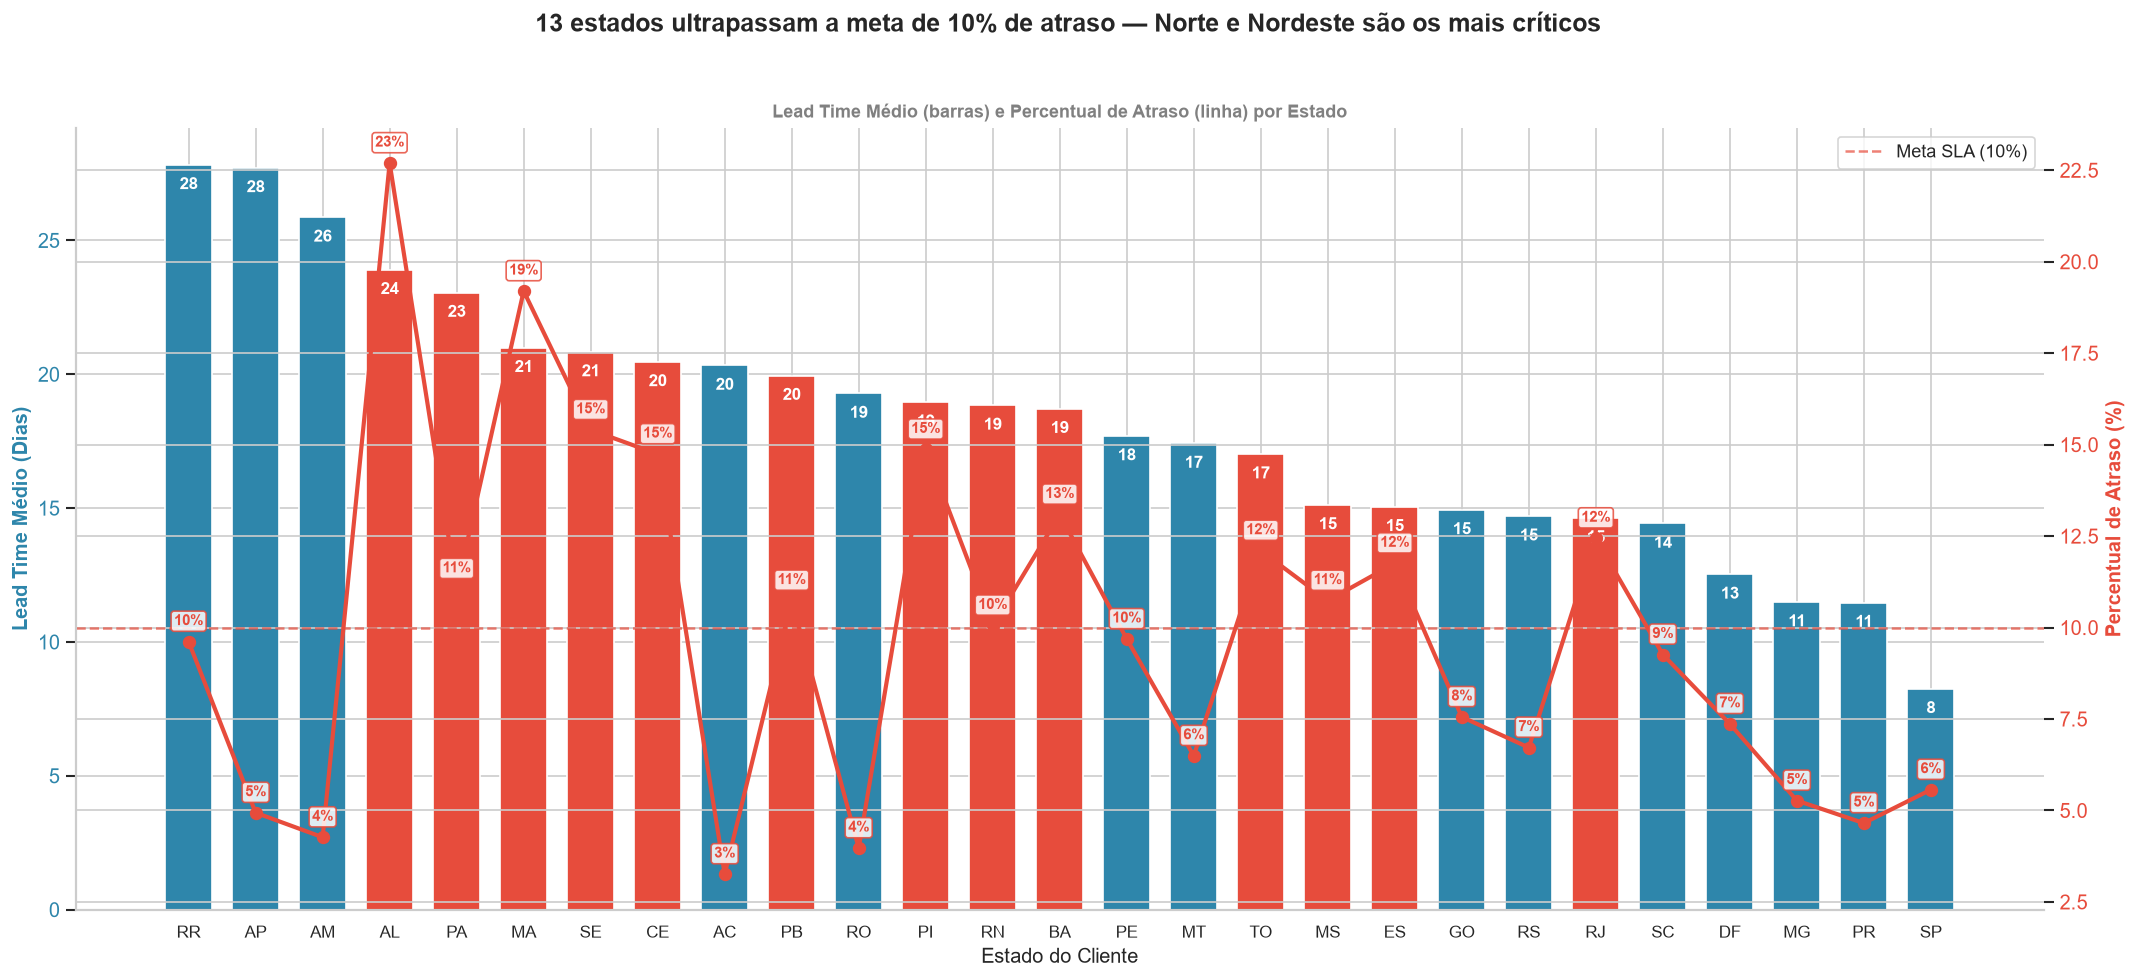

In [21]:
# === PREPARAÇÃO DOS DADOS DE ENTREGA ===
merged_df['lead_time'] = (merged_df['order_delivered_customer_date'] - merged_df['order_purchase_timestamp']).dt.days
merged_df['is_delayed'] = merged_df['order_delivered_customer_date'] > merged_df['order_estimated_delivery_date']

state_stats = merged_df.groupby('customer_state').agg(
    lead_time_medio=('lead_time', 'mean'),
    total_pedidos=('order_id', 'count'),
    pedidos_atrasados=('is_delayed', 'sum')
).reset_index()

state_stats['perc_atraso'] = (state_stats['pedidos_atrasados'] / state_stats['total_pedidos']) * 100
state_stats = state_stats.sort_values('lead_time_medio', ascending=False)

# Quantos estados acima da meta
META_SLA = 10  # Meta de atraso máximo aceitável (%)
estados_criticos = state_stats[state_stats['perc_atraso'] > META_SLA].shape[0]

# === GRÁFICO MISTO: BARRAS + LINHA COM SLA ===
fig, ax1 = plt.subplots(figsize=(18, 8))

# Barras coloridas: azul se dentro da meta, vermelho se acima
cores_barras = [COR_ALERTA if p > META_SLA else COR_PRINCIPAL for p in state_stats['perc_atraso']]
bars = ax1.bar(range(len(state_stats)), state_stats['lead_time_medio'], color=cores_barras, width=0.7, zorder=2)
ax1.set_xticks(range(len(state_stats)))
ax1.set_xticklabels(state_stats['customer_state'], fontsize=10)
ax1.set_ylabel('Lead Time Médio (Dias)', color=COR_PRINCIPAL, fontsize=12, fontweight='bold')
ax1.set_xlabel('Estado do Cliente', fontsize=12)
ax1.tick_params(axis='y', labelcolor=COR_PRINCIPAL)

# Rótulos nas barras
for bar in bars:
    ax1.annotate(f"{int(round(bar.get_height()))}",
                 (bar.get_x() + bar.get_width() / 2., bar.get_height()),
                 ha='center', va='center', xytext=(0, -12), textcoords='offset points',
                 color='white', fontweight='bold', fontsize=10)

# Segundo eixo: linha de % atraso
ax2 = ax1.twinx()
ax2.plot(range(len(state_stats)), state_stats['perc_atraso'].values, color=COR_LINHA, 
         marker='o', linewidth=2.5, markersize=7, zorder=3)
ax2.set_ylabel('Percentual de Atraso (%)', color=COR_LINHA, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=COR_LINHA)

# Rótulos na linha
for i, val in enumerate(state_stats['perc_atraso'].values):
    ax2.annotate(f"{val:.0f}%", (i, val), ha='center', va='bottom',
                 xytext=(0, 8), textcoords='offset points', color=COR_LINHA, fontweight='bold', fontsize=9,
                 bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=COR_LINHA, lw=1, alpha=0.85))

# === LINHA DE META SLA ===
ax2.axhline(y=META_SLA, color=COR_ALERTA, linestyle='--', linewidth=1.5, alpha=0.7, label=f'Meta SLA ({META_SLA}%)')
ax2.legend(loc='upper right', fontsize=11)

# Título com insight
fig.suptitle(f'{estados_criticos} estados ultrapassam a meta de {META_SLA}% de atraso — Norte e Nordeste são os mais críticos',
             fontsize=15, fontweight='bold', y=1.02)
ax1.set_title('Lead Time Médio (barras) e Percentual de Atraso (linha) por Estado', fontsize=11, color='gray')

plt.tight_layout()
plt.show()


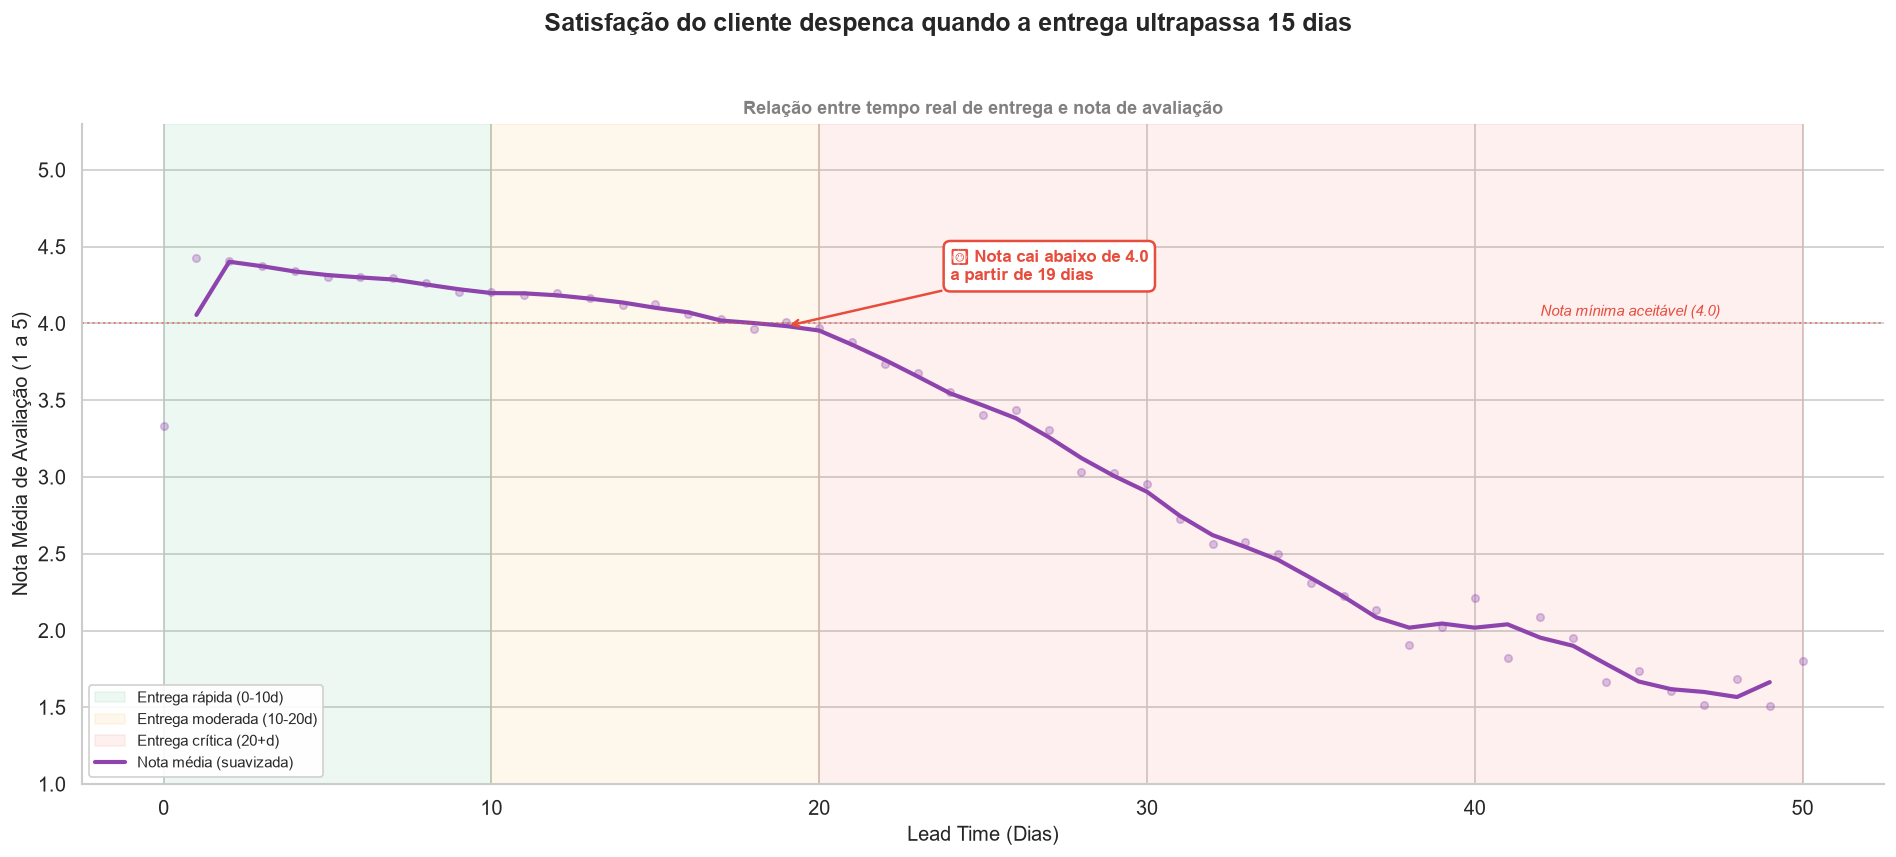

In [22]:
# === SATISFAÇÃO DO CLIENTE x TEMPO DE ENTREGA ===
review_data = merged_df.dropna(subset=['lead_time']).copy()
review_data = review_data[(review_data['lead_time'] >= 0) & (review_data['lead_time'] <= 50)]

review_by_lt = review_data.groupby('lead_time').agg(
    review_medio=('review_score', 'mean'),
    volume=('review_id', 'count')
).reset_index()

# Suavizar com média móvel de 3 dias
review_by_lt['review_suavizado'] = review_by_lt['review_medio'].rolling(window=3, center=True).mean()

fig, ax = plt.subplots(figsize=(16, 7))

# Faixas coloridas de contexto
ax.axvspan(0, 10, alpha=0.08, color=COR_SUCESSO, label='Entrega rápida (0-10d)')
ax.axvspan(10, 20, alpha=0.08, color=COR_DESTAQUE, label='Entrega moderada (10-20d)')
ax.axvspan(20, 50, alpha=0.08, color=COR_ALERTA, label='Entrega crítica (20+d)')

# Linha suavizada
ax.plot(review_by_lt['lead_time'], review_by_lt['review_suavizado'], 
        color='#8E44AD', linewidth=2.5, label='Nota média (suavizada)')

# Pontos originais com transparência
ax.scatter(review_by_lt['lead_time'], review_by_lt['review_medio'], 
           color='#8E44AD', alpha=0.3, s=20, zorder=2)

# Linha de referência: nota 4.0
ax.axhline(y=4.0, color=COR_ALERTA, linestyle=':', linewidth=1.2, alpha=0.6)
ax.annotate('Nota mínima aceitável (4.0)', xy=(42, 4.05), fontsize=9, color=COR_ALERTA, fontstyle='italic')

# Encontrar o ponto onde a nota cruza abaixo de 4.0
cruzamento = review_by_lt[review_by_lt['review_suavizado'] < 4.0]
if not cruzamento.empty:
    dia_critico = cruzamento.iloc[0]['lead_time']
    nota_critica = cruzamento.iloc[0]['review_suavizado']
    ax.annotate(f'⚠ Nota cai abaixo de 4.0\na partir de {int(dia_critico)} dias',
                xy=(dia_critico, nota_critica), xytext=(dia_critico + 5, nota_critica + 0.3),
                fontsize=10, fontweight='bold', color=COR_ALERTA,
                arrowprops=dict(arrowstyle='->', color=COR_ALERTA, lw=1.5),
                bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=COR_ALERTA, lw=1.5))

ax.set_xlabel('Lead Time (Dias)')
ax.set_ylabel('Nota Média de Avaliação (1 a 5)')
ax.set_ylim(1, 5.3)
ax.legend(loc='lower left', fontsize=9, framealpha=0.9)

fig.suptitle('Satisfação do cliente despenca quando a entrega ultrapassa 15 dias',
             fontsize=15, fontweight='bold', y=1.02)
ax.set_title('Relação entre tempo real de entrega e nota de avaliação', fontsize=11, color='gray')

plt.tight_layout()
plt.show()


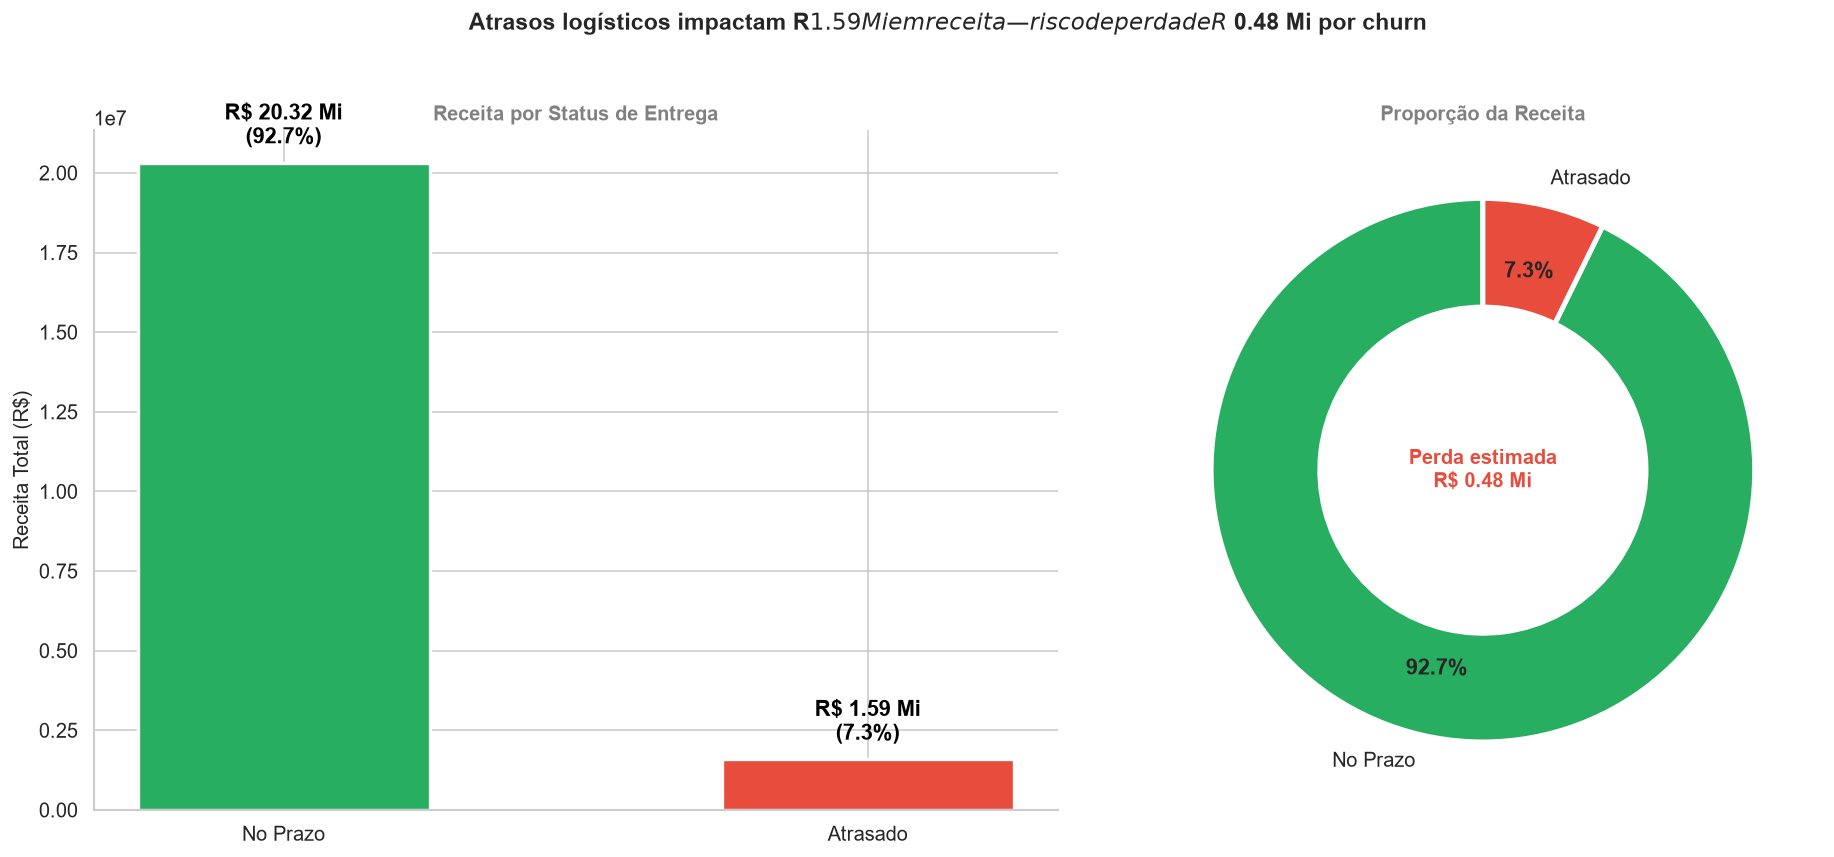

In [23]:
# === IMPACTO FINANCEIRO: ENTREGAS NO PRAZO vs ATRASADAS ===
fin = merged_df.dropna(subset=['is_delayed']).groupby('is_delayed').agg(
    receita=('price', 'sum'),
    qtd_pedidos=('order_id', 'nunique')
).reset_index()

fin['label'] = fin['is_delayed'].map({False: 'No Prazo', True: 'Atrasado'})
receita_total = fin['receita'].sum()
fin['pct'] = (fin['receita'] / receita_total) * 100

# Receita perdida estimada (supondo que 30% dos clientes de pedidos atrasados não voltam)
receita_atrasada = fin.loc[fin['is_delayed'] == True, 'receita'].values
perda_estimada = receita_atrasada[0] * 0.30 if len(receita_atrasada) > 0 else 0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.2, 1]})

# Gráfico de barras
cores = [COR_SUCESSO, COR_ALERTA]
bars = ax1.bar(fin['label'], fin['receita'], color=cores, width=0.5, edgecolor='white', linewidth=2)

for bar, pct_val in zip(bars, fin['pct']):
    ax1.annotate(f"R$ {bar.get_height()/1e6:.2f} Mi\n({pct_val:.1f}%)",
                 (bar.get_x() + bar.get_width() / 2., bar.get_height()),
                 ha='center', va='bottom', xytext=(0, 8), textcoords='offset points',
                 fontweight='bold', fontsize=13, color='black')

ax1.set_ylabel('Receita Total (R$)')
ax1.set_title('Receita por Status de Entrega', fontsize=12, color='gray')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# Gráfico de rosca (donut)
wedges, texts, autotexts = ax2.pie(fin['receita'], labels=fin['label'], autopct='%1.1f%%',
                                    colors=cores, startangle=90, pctdistance=0.75,
                                    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=3))
for t in autotexts:
    t.set_fontsize(13)
    t.set_fontweight('bold')
for t in texts:
    t.set_fontsize(12)

ax2.set_title('Proporção da Receita', fontsize=12, color='gray')

# KPI no centro do donut
ax2.text(0, 0, f"Perda estimada\nR$ {perda_estimada/1e6:.2f} Mi", ha='center', va='center',
         fontsize=12, fontweight='bold', color=COR_ALERTA)

fig.suptitle(f'Atrasos logísticos impactam R$ {receita_atrasada[0]/1e6:.2f} Mi em receita — risco de perda de R$ {perda_estimada/1e6:.2f} Mi por churn',
             fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()


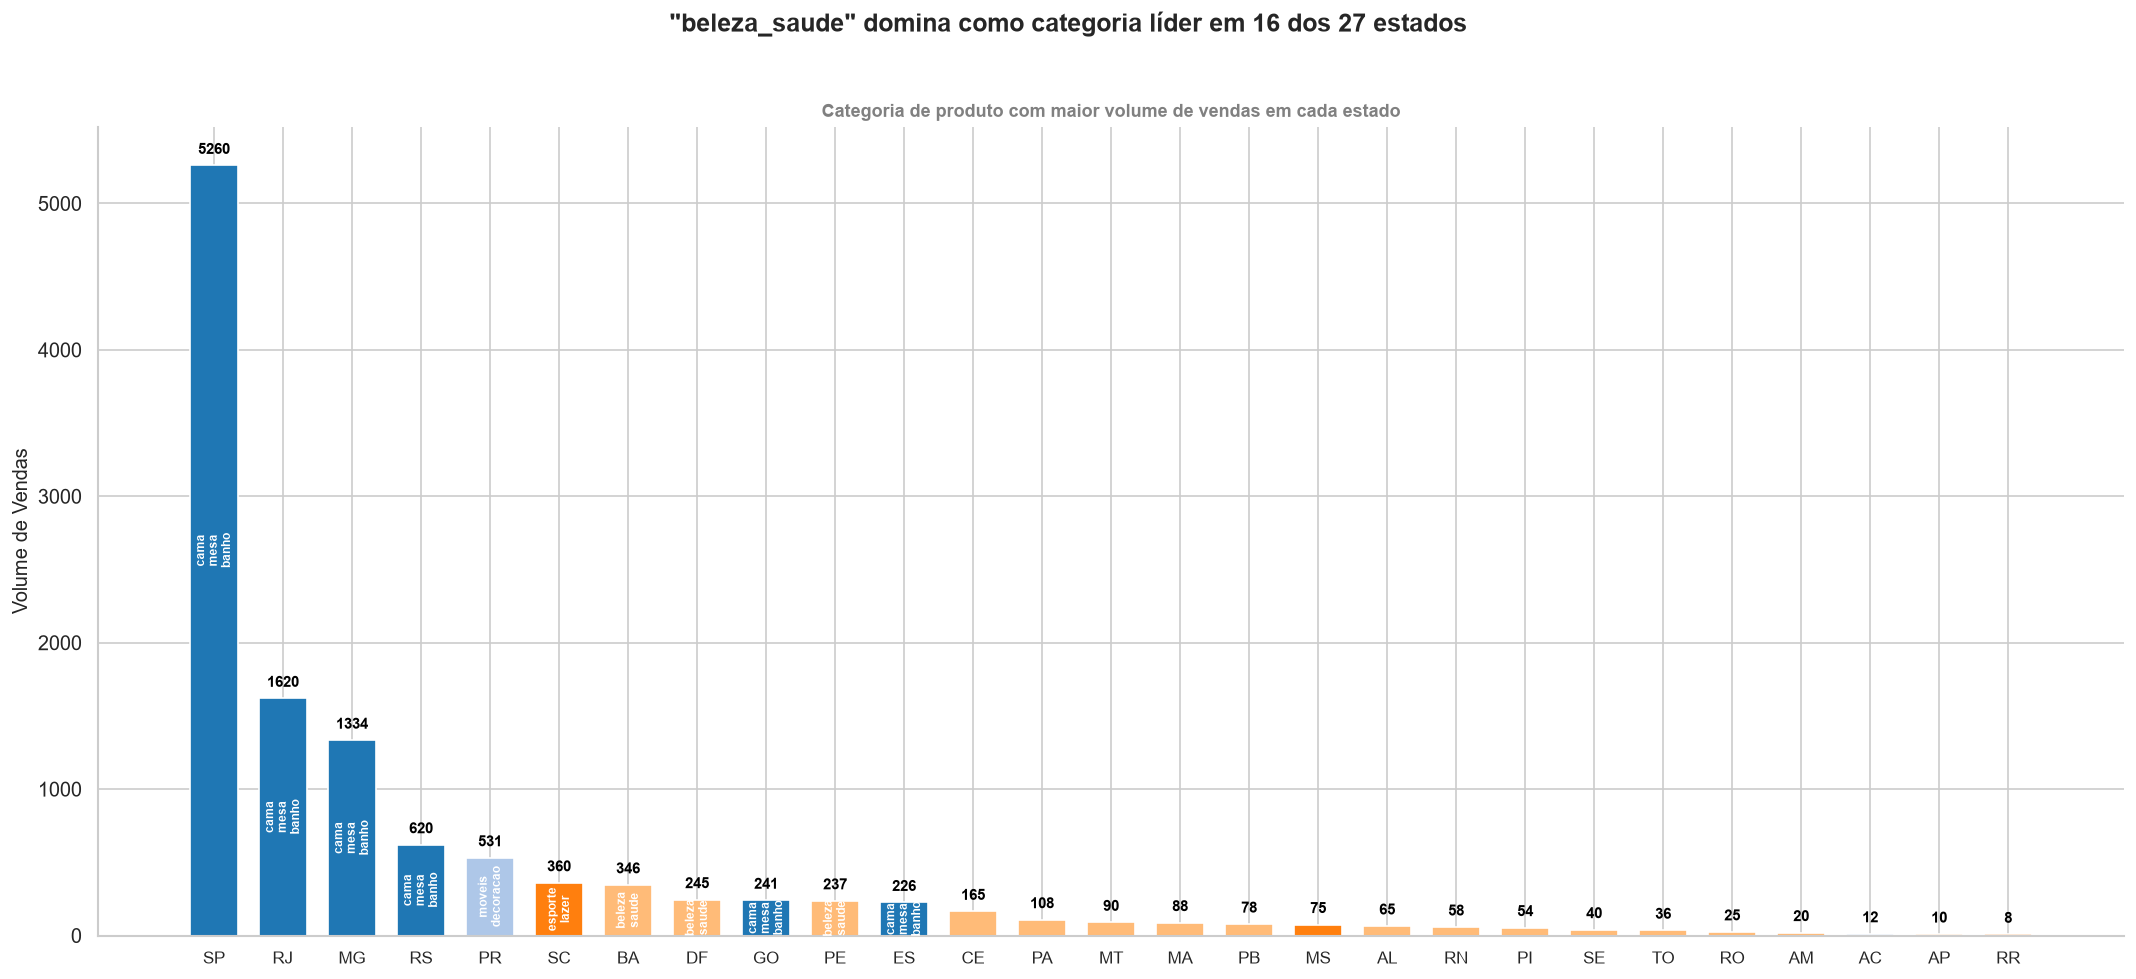

In [24]:
# === CATEGORIA MAIS VENDIDA POR ESTADO ===
import pandas as pd
import os

if os.path.exists(r'Dados excel/olist_products_dataset.xlsx'):
    df_products = pd.read_excel(r'Dados excel/olist_products_dataset.xlsx')
else:
    df_products = pd.read_excel(file_path, sheet_name='Products')

merged_df_prod = pd.merge(merged_df, df_products[['product_id', 'product_category_name']], on='product_id', how='left')
merged_df_prod['product_category_name'] = merged_df_prod['product_category_name'].fillna('desconhecido')

# Top 1 categoria por estado
prod_estado = merged_df_prod.groupby(['customer_state', 'product_category_name']).size().reset_index(name='qtd')
top_por_estado = prod_estado.loc[prod_estado.groupby('customer_state')['qtd'].idxmax()]
top_por_estado = top_por_estado.sort_values('qtd', ascending=False)

# Criar cor por categoria (categorias iguais = mesma cor)
categorias_unicas = top_por_estado['product_category_name'].unique()
paleta = sns.color_palette('tab20', n_colors=len(categorias_unicas))
mapa_cores = {cat: paleta[i] for i, cat in enumerate(categorias_unicas)}
cores = [mapa_cores[cat] for cat in top_por_estado['product_category_name']]

fig, ax = plt.subplots(figsize=(18, 8))
bars = ax.bar(range(len(top_por_estado)), top_por_estado['qtd'], color=cores, width=0.7, edgecolor='white')
ax.set_xticks(range(len(top_por_estado)))
ax.set_xticklabels(top_por_estado['customer_state'], fontsize=10)

# Rótulos: nome da categoria + volume
for i, (bar, (_, row)) in enumerate(zip(bars, top_por_estado.iterrows())):
    # Volume em cima
    ax.annotate(f"{int(row['qtd'])}",
                (bar.get_x() + bar.get_width() / 2., bar.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points',
                fontweight='bold', fontsize=9, color='black')
    # Categoria dentro da barra (rotacionada)
    cat_label = row['product_category_name'].replace('_', '\n')
    if bar.get_height() > 200:  # Só mostra texto se a barra for grande o suficiente
        ax.text(bar.get_x() + bar.get_width() / 2., bar.get_height() / 2., cat_label,
                ha='center', va='center', fontsize=7, color='white', fontweight='bold', rotation=90)

ax.set_ylabel('Volume de Vendas')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Contar categoria dominante
cat_dominante = top_por_estado['product_category_name'].value_counts().idxmax()
cat_dom_count = top_por_estado['product_category_name'].value_counts().max()

fig.suptitle(f'"{cat_dominante}" domina como categoria líder em {cat_dom_count} dos 27 estados',
             fontsize=15, fontweight='bold', y=1.02)
ax.set_title('Categoria de produto com maior volume de vendas em cada estado', fontsize=11, color='gray')

plt.tight_layout()
plt.show()


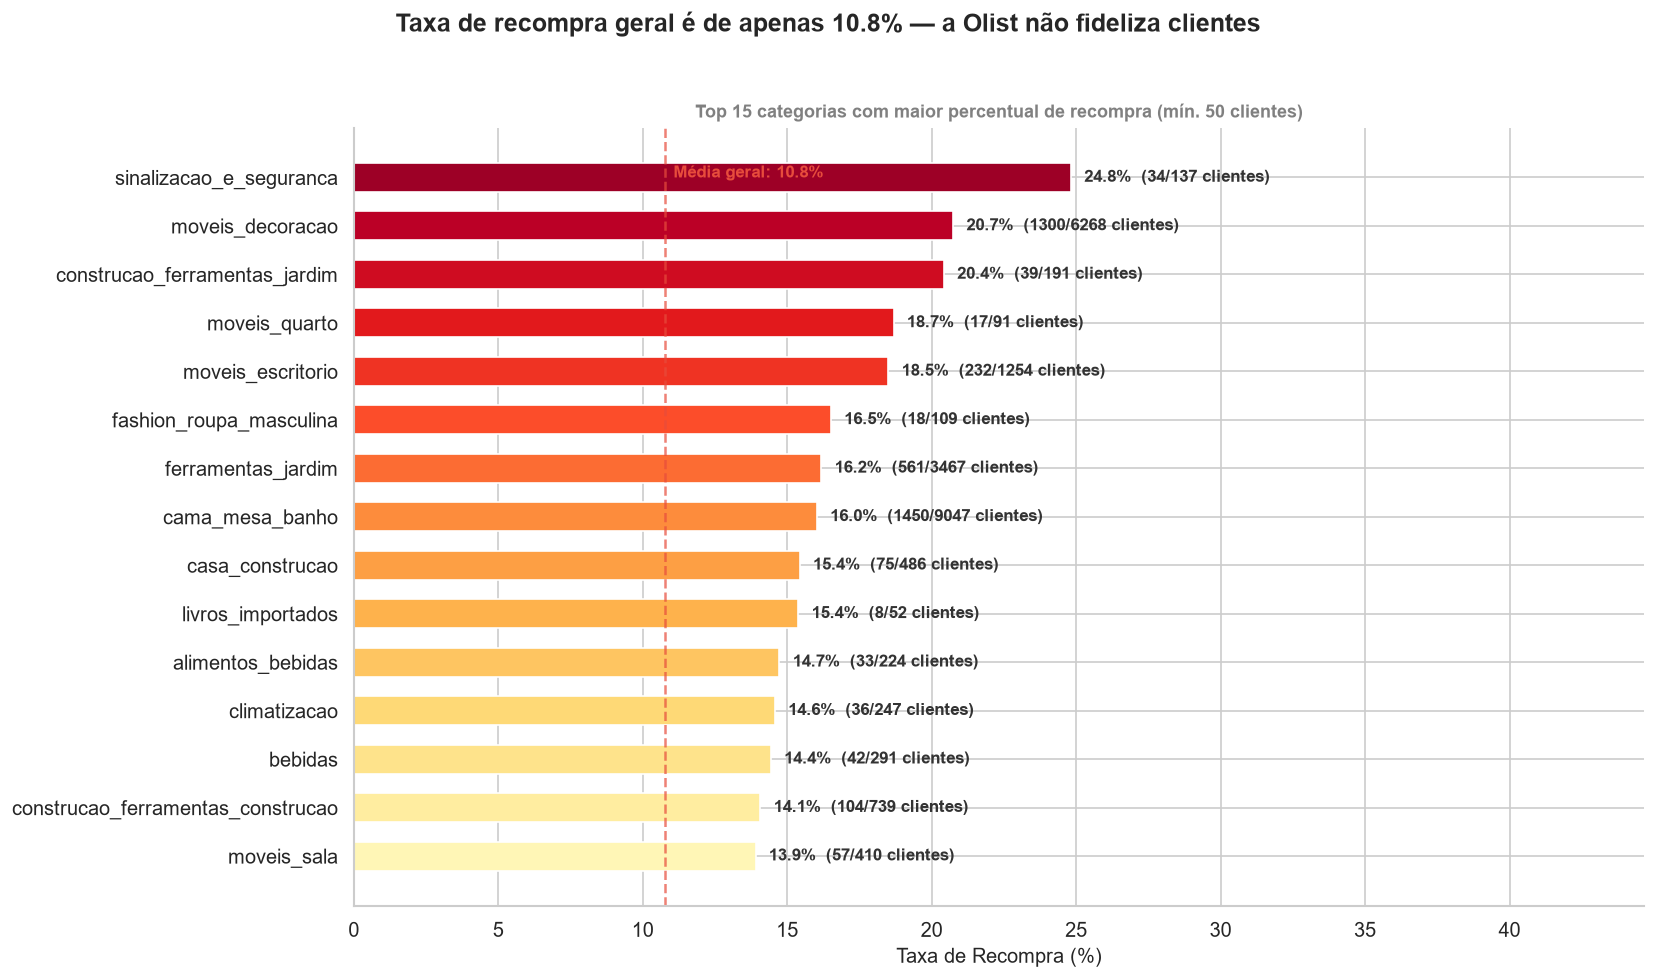

In [25]:
# === TAXA DE RECOMPRA POR CATEGORIA ===
recompra = merged_df_prod.groupby(['product_category_name', 'customer_unique_id']).size().reset_index(name='qtd_compras')
recompra['recomprou'] = recompra['qtd_compras'] > 1

por_cat = recompra.groupby('product_category_name').agg(
    total_clientes=('customer_unique_id', 'count'),
    recompraram=('recomprou', 'sum')
).reset_index()

por_cat = por_cat[por_cat['total_clientes'] >= 50]
por_cat['taxa'] = (por_cat['recompraram'] / por_cat['total_clientes']) * 100
por_cat = por_cat.sort_values('taxa', ascending=True).tail(15)

# Taxa geral de recompra
total_clientes_geral = recompra['customer_unique_id'].nunique()
total_recompraram = recompra[recompra['recomprou']].customer_unique_id.nunique()
taxa_geral = (total_recompraram / total_clientes_geral) * 100

fig, ax = plt.subplots(figsize=(14, 8))

# Barras horizontais com cores gradientes
cores = sns.color_palette('YlOrRd', n_colors=len(por_cat))
bars = ax.barh(por_cat['product_category_name'], por_cat['taxa'], color=cores, edgecolor='white', height=0.6)

# Rótulos nas barras: taxa + volume de clientes
for bar, (_, row) in zip(bars, por_cat.iterrows()):
    ax.annotate(f"{row['taxa']:.1f}%  ({int(row['recompraram'])}/{int(row['total_clientes'])} clientes)",
                (bar.get_width(), bar.get_y() + bar.get_height() / 2.),
                ha='left', va='center', xytext=(8, 0), textcoords='offset points',
                fontweight='bold', fontsize=10, color='#333')

# Linha vertical de referência: taxa geral
ax.axvline(x=taxa_geral, color=COR_ALERTA, linestyle='--', linewidth=1.5, alpha=0.7)
ax.annotate(f'Média geral: {taxa_geral:.1f}%', xy=(taxa_geral + 0.3, len(por_cat) - 1),
            fontsize=10, color=COR_ALERTA, fontweight='bold')

ax.set_xlabel('Taxa de Recompra (%)')
ax.set_ylabel('')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Expandir xlim para caber os rótulos
max_taxa = por_cat['taxa'].max()
ax.set_xlim(0, max_taxa * 1.8)

fig.suptitle(f'Taxa de recompra geral é de apenas {taxa_geral:.1f}% — a Olist não fideliza clientes',
             fontsize=15, fontweight='bold', y=1.02)
ax.set_title('Top 15 categorias com maior percentual de recompra (mín. 50 clientes)', fontsize=11, color='gray')

plt.tight_layout()
plt.show()
